In [1]:
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.axes import Axes
from matplotlib.figure import Figure


import argparse
from collections.abc import Iterable
from dataclasses import dataclass
from pathlib import Path

from scipy.stats import pearsonr, spearmanr
import pandas as pd

import torch
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn

In [2]:
def load_h5(filepath: str | Path, filename: str) -> dict[str, np.ndarray]:
    """
    Load all datasets from an HDF5 file.

    Parameters
    ----------
    filepath
        Directory containing the HDF5 file.

    filename
        Name of the HDF5 file, including the .h5 extension.

    Returns
    -------
    dict[str, np.ndarray]
        Dictionary containing all HDF5 datasets.

        The dictionary keys are the full dataset paths inside the
        HDF5 file. The values are NumPy arrays.

    Raises
    ------
    FileNotFoundError
        If the requested HDF5 file does not exist.

    OSError
        If the file exists but cannot be opened as an HDF5 file.
    """
    full_path = Path(filepath) / filename

    if not full_path.is_file():
        raise FileNotFoundError(
            f"HDF5 file was not found: {full_path.resolve()}"
        )

    data: dict[str, np.ndarray] = {}

    with h5py.File(full_path, mode="r") as h5_file:

        def load_dataset(name: str, obj: h5py.Dataset | h5py.Group) -> None:
            if isinstance(obj, h5py.Dataset):
                data[name] = obj[...]

        h5_file.visititems(load_dataset)

    return data

In [3]:
parent_dir = Path("/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/datasets/BasC/param_space")

# case_names = [
#     "Re010_Ca0_010_theta45",
#     "Re010_Ca0_010_theta45_v2",
#     "Re020_Ca0_010_theta45",
#     "Re050_Ca0_010_theta45",
#     "Re120_Ca0_010_theta45",
# ]

case_names = [
    "Re010_Ca0_010_theta45",
    "Re050_Ca0_010_theta45",
    "Re120_Ca0_010_theta45",
]

filename = "thinfilm_closure_data.h5"

all_closure_data = {}

for case_name in case_names:
    case_dir = parent_dir / case_name
    file_path = case_dir / filename

    if file_path.exists():
        all_closure_data[case_name] = load_h5(case_dir, filename)
        print(f"Loaded: {case_name}")
    else:
        print(f"Missing: {file_path}")

Loaded: Re010_Ca0_010_theta45
Loaded: Re050_Ca0_010_theta45
Loaded: Re120_Ca0_010_theta45


In [4]:
for case_name, closure_data in all_closure_data.items():
    print(f"\n{case_name}")
    print("-" * len(case_name))

    for key, value in closure_data.items():
        print(f"  {key:<35} shape={value.shape}, dtype={value.dtype}")


Re010_Ca0_010_theta45
---------------------
  dt                                  shape=(103,), dtype=float64
  h                                   shape=(16384, 103), dtype=float64
  h_m                                 shape=(16384, 103), dtype=float64
  h_x                                 shape=(16384, 103), dtype=float64
  h_xx                                shape=(16384, 103), dtype=float64
  parameters/Ca                       shape=(), dtype=float64
  parameters/Re                       shape=(), dtype=float64
  parameters/angle                    shape=(), dtype=float64
  parameters/h0                       shape=(), dtype=float64
  parameters/mu_ratio                 shape=(), dtype=float64
  parameters/rho_ratio                shape=(), dtype=float64
  parameters/t0                       shape=(), dtype=float64
  parameters/u0                       shape=(), dtype=float64
  q                                   shape=(16384, 103), dtype=float64
  q_m                            

In [5]:
def first_derivative_x(
    x: np.ndarray,
    field: np.ndarray,
) -> np.ndarray:
    """
    Compute the first derivative with respect to x for a field
    stored as (nx, nt).

    Fourth-order central differences are used in the interior.
    Fourth-order one-sided differences are used near the boundaries.

    Parameters
    ----------
    x : ndarray, shape (nx,)
        Uniformly spaced x coordinates.

    field : ndarray, shape (nx, nt)
        Field values. The first axis must correspond to x.

        Examples:
            h
            q
            tau_wall
            shape_factor

    Returns
    -------
    dfield_dx : ndarray, shape (nx, nt)
        Fourth-order approximation to df/dx at every time.
    """

    x = np.asarray(x, dtype=float)
    field = np.asarray(field, dtype=float)

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    if x.ndim != 1:
        raise ValueError(
            "x must be a one-dimensional array."
        )

    if field.ndim != 2:
        raise ValueError(
            "field must have shape (nx, nt)."
        )

    if field.shape[0] != x.size:
        raise ValueError(
            "The first dimension of field must equal len(x). "
            f"Received field.shape={field.shape}, "
            f"len(x)={x.size}."
        )

    if x.size < 5:
        raise ValueError(
            "At least five x points are required for "
            "fourth-order differentiation."
        )

    dx_values = np.diff(x)
    dx = dx_values[0]

    if dx <= 0.0:
        raise ValueError(
            "x coordinates must increase monotonically."
        )

    if not np.allclose(dx_values, dx):
        raise ValueError(
            "The x grid must be uniformly spaced."
        )

    dfield_dx = np.empty_like(field, dtype=float)

    # --------------------------------------------------------
    # Interior
    # Fourth-order central difference
    # --------------------------------------------------------

    dfield_dx[2:-2, :] = (
        field[:-4, :]
        - 8.0 * field[1:-3, :]
        + 8.0 * field[3:-1, :]
        - field[4:, :]
    ) / (12.0 * dx)

    # --------------------------------------------------------
    # Left boundary
    # --------------------------------------------------------

    dfield_dx[0, :] = (
        -25.0 * field[0, :]
        + 48.0 * field[1, :]
        - 36.0 * field[2, :]
        + 16.0 * field[3, :]
        - 3.0 * field[4, :]
    ) / (12.0 * dx)

    dfield_dx[1, :] = (
        -3.0 * field[0, :]
        - 10.0 * field[1, :]
        + 18.0 * field[2, :]
        - 6.0 * field[3, :]
        + field[4, :]
    ) / (12.0 * dx)

    # --------------------------------------------------------
    # Right boundary
    # --------------------------------------------------------

    dfield_dx[-2, :] = (
        -field[-5, :]
        + 6.0 * field[-4, :]
        - 18.0 * field[-3, :]
        + 10.0 * field[-2, :]
        + 3.0 * field[-1, :]
    ) / (12.0 * dx)

    dfield_dx[-1, :] = (
        3.0 * field[-5, :]
        - 16.0 * field[-4, :]
        + 36.0 * field[-3, :]
        - 48.0 * field[-2, :]
        + 25.0 * field[-1, :]
    ) / (12.0 * dx)

    return dfield_dx

In [6]:
def second_derivative_x(
    x: np.ndarray,
    field: np.ndarray,
) -> np.ndarray:
    """
    Compute the second derivative with respect to x for a field
    stored as (nx, nt).

    Fourth-order central differences are used in the interior.
    Fourth-order one-sided differences are used near boundaries.

    Parameters
    ----------
    x : ndarray, shape (nx,)
        Uniformly spaced x coordinates.

    field : ndarray, shape (nx, nt)
        Field values. The first axis corresponds to x.

    Returns
    -------
    d2field_dx2 : ndarray, shape (nx, nt)
        Fourth-order approximation to d²f/dx².
    """

    x = np.asarray(x, dtype=float)
    field = np.asarray(field, dtype=float)

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    if x.ndim != 1:
        raise ValueError(
            "x must be one-dimensional."
        )

    if field.ndim != 2:
        raise ValueError(
            "field must have shape (nx, nt)."
        )

    if field.shape[0] != x.size:
        raise ValueError(
            "The first dimension of field must equal len(x). "
            f"Received field.shape={field.shape}, "
            f"len(x)={x.size}."
        )

    if x.size < 6:
        raise ValueError(
            "At least six x points are required."
        )

    dx_values = np.diff(x)
    dx = dx_values[0]

    if dx <= 0.0:
        raise ValueError(
            "x coordinates must increase monotonically."
        )

    if not np.allclose(dx_values, dx):
        raise ValueError(
            "The x grid must be uniformly spaced."
        )

    d2field_dx2 = np.empty_like(
        field,
        dtype=float,
    )

    # --------------------------------------------------------
    # Interior
    # --------------------------------------------------------

    d2field_dx2[2:-2, :] = (
        -field[4:, :]
        + 16.0 * field[3:-1, :]
        - 30.0 * field[2:-2, :]
        + 16.0 * field[1:-3, :]
        - field[:-4, :]
    ) / (12.0 * dx**2)

    # --------------------------------------------------------
    # Left boundary
    # --------------------------------------------------------

    d2field_dx2[0, :] = (
        45.0 * field[0, :]
        - 154.0 * field[1, :]
        + 214.0 * field[2, :]
        - 156.0 * field[3, :]
        + 61.0 * field[4, :]
        - 10.0 * field[5, :]
    ) / (12.0 * dx**2)

    d2field_dx2[1, :] = (
        10.0 * field[0, :]
        - 15.0 * field[1, :]
        - 4.0 * field[2, :]
        + 14.0 * field[3, :]
        - 6.0 * field[4, :]
        + field[5, :]
    ) / (12.0 * dx**2)

    # --------------------------------------------------------
    # Right boundary
    # --------------------------------------------------------

    d2field_dx2[-2, :] = (
        field[-6, :]
        - 6.0 * field[-5, :]
        + 14.0 * field[-4, :]
        - 4.0 * field[-3, :]
        - 15.0 * field[-2, :]
        + 10.0 * field[-1, :]
    ) / (12.0 * dx**2)

    d2field_dx2[-1, :] = (
        -10.0 * field[-6, :]
        + 61.0 * field[-5, :]
        - 156.0 * field[-4, :]
        + 214.0 * field[-3, :]
        - 154.0 * field[-2, :]
        + 45.0 * field[-1, :]
    ) / (12.0 * dx**2)

    return d2field_dx2

In [7]:
def first_derivative_t(
    field: np.ndarray,
    field_minus: np.ndarray,
    time: np.ndarray,
    time_minus: np.ndarray,
) -> np.ndarray:
    """
    Compute first-order backward time derivatives for a field
    stored as (nx, nt).

    Each current snapshot has a corresponding previous snapshot:

        df/dt[:, j] =
            (field[:, j] - field_minus[:, j])
            / (time[j] - time_minus[j])

    Parameters
    ----------
    field : ndarray, shape (nx, nt)
        Quantity at the current snapshot times.

    field_minus : ndarray, shape (nx, nt)
        Same quantity at the corresponding previous times.

    time : ndarray, shape (nt,)
        Current snapshot times.

    time_minus : ndarray, shape (nt,)
        Previous snapshot times.

    Returns
    -------
    dfield_dt : ndarray, shape (nx, nt)
        First-order approximation to df/dt.
    """

    field = np.asarray(field, dtype=float)
    field_minus = np.asarray(field_minus, dtype=float)

    time = np.asarray(time, dtype=float)
    time_minus = np.asarray(time_minus, dtype=float)

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    if field.ndim != 2:
        raise ValueError(
            "field must have shape (nx, nt)."
        )

    if field_minus.ndim != 2:
        raise ValueError(
            "field_minus must have shape (nx, nt)."
        )

    if field.shape != field_minus.shape:
        raise ValueError(
            "field and field_minus must have identical shapes. "
            f"Received {field.shape} and {field_minus.shape}."
        )

    if time.ndim != 1 or time_minus.ndim != 1:
        raise ValueError(
            "time and time_minus must be one-dimensional."
        )

    if time.shape != time_minus.shape:
        raise ValueError(
            "time and time_minus must have identical shapes."
        )

    if field.shape[1] != time.size:
        raise ValueError(
            "The second dimension of field must match "
            "the number of time values. "
            f"Received field.shape={field.shape}, "
            f"time.size={time.size}."
        )

    dt = time - time_minus

    if np.any(dt <= 0.0):
        bad_indices = np.where(dt <= 0.0)[0]

        raise ValueError(
            "All time values must be greater than their "
            "corresponding time_minus values. "
            f"Bad indices: {bad_indices[:10]}"
        )

    # dt has shape (nt,)
    #
    # field has shape (nx, nt)
    #
    # NumPy broadcasts dt across the x dimension.

    dfield_dt = (
        field - field_minus
    ) / dt[np.newaxis, :]

    return dfield_dt

Interface plots for all cases

In [8]:
for case_name, data in all_closure_data.items():
    t_case = data["t"]

    print(f"{case_name:<30} t_max = {np.max(t_case):10.4f}    snapshots = {len(t_case)}")

Re010_Ca0_010_theta45          t_max =  1030.0000    snapshots = 103
Re050_Ca0_010_theta45          t_max =  1060.0000    snapshots = 106
Re120_Ca0_010_theta45          t_max =  1900.0000    snapshots = 190


In [9]:
h_mean = 1.0
h_tolerance = 0.1

analysis_masks = {}

for case_name, data in all_closure_data.items():

    x_case = data["x"]
    h_case = data["h"]
    t_case = data["t"]

    nx, nt = h_case.shape

    analysis_mask = np.zeros((nx, nt), dtype=bool)

    for j in range(nt):

        h_snapshot = h_case[:, j]

        flat = np.abs(h_snapshot - h_mean) <= h_tolerance
        disturbed = ~flat

        disturbed_indices = np.where(disturbed)[0]

        if disturbed_indices.size == 0:
            continue

        last_disturbed_index = disturbed_indices[-1]

        analysis_mask[:last_disturbed_index + 1, j] = True

    analysis_masks[case_name] = analysis_mask

    retained = np.sum(analysis_mask)
    total = analysis_mask.size

    print(f"{case_name:<30} retained = {retained / total * 100:.2f}%")

Re010_Ca0_010_theta45          retained = 88.13%
Re050_Ca0_010_theta45          retained = 84.83%
Re120_Ca0_010_theta45          retained = 89.78%


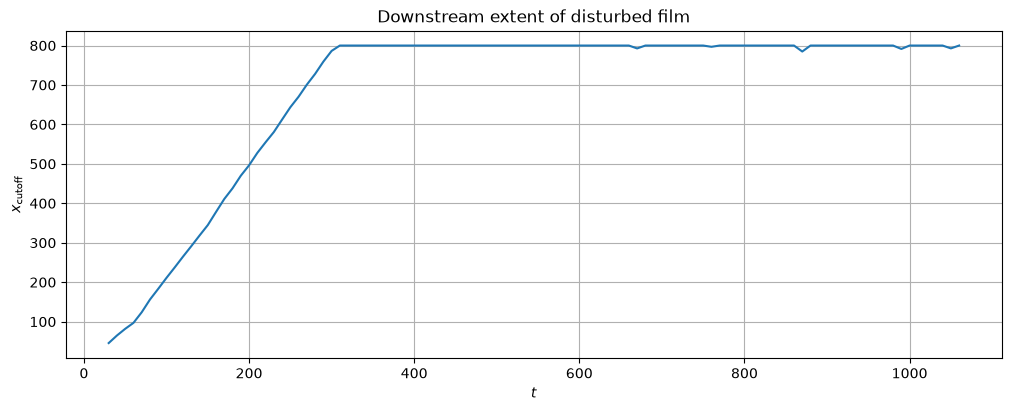

In [10]:
case_name = "Re050_Ca0_010_theta45"

data = all_closure_data[case_name]

x_case = data["x"]
h_case = data["h"]
t_case = data["t"]

mask = analysis_masks[case_name]

x_cutoff = np.full(len(t_case), np.nan)

for j in range(len(t_case)):

    retained_indices = np.where(mask[:, j])[0]

    if retained_indices.size > 0:
        x_cutoff[j] = x_case[retained_indices[-1]]

fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)

ax.plot(t_case, x_cutoff)

ax.set_xlabel(r"$t$")
ax.set_ylabel(r"$x_{\mathrm{cutoff}}$")
ax.set_title("Downstream extent of disturbed film")
ax.grid(True)

plt.show()

## Multi-output local-window model

Predicts `tau_wall`, the dimensionless shape factor $\Phi = (\int_0^h u^2\,dy)/(q^2/h)$, and `u_interface` from local windows of `h` and `q`.

For the CNN, the input channels are `h`, `q`, `Re`, and the physical grid spacing `dx`. The `dx` channel is repeated across the local stencil so the network can distinguish the same index-space stencil sampled at different physical resolutions.


In [11]:
# Model dependencies (kept here so either notebook is self-contained).
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# Architecture and training configuration
k_space = 4
window_size = 2 * k_space + 1

# Change these to compare model capacity.
n_hidden_layers = 4
hidden_neurons = 64

batch_size = 8192
n_epochs = 100
learning_rate = 1.0e-3
samples_per_case = 150000
random_seed = 42

# The HDF5 field currently called "shape_factor" is treated here as the
# raw momentum integral I2 = integral_0^h u^2 dy, following the previous
# notebook convention. The actual ML target is computed below as
# Phi = I2 / (q^2/h) = I2*h/q^2.
momentum_integral_field = "shape_factor"
target_names = ["tau_wall", "shape_factor", "u_interface"]
target_labels = [r"$\tau_w$", r"$\Phi = \dfrac{\int_0^h u^2\,dy}{q^2/h}$", r"$u_i$"]

if k_space < 0:
    raise ValueError("k_space must be non-negative.")
if n_hidden_layers < 1:
    raise ValueError("n_hidden_layers must be at least one.")
if hidden_neurons < 1:
    raise ValueError("hidden_neurons must be positive.")

required_fields = {"h", "q", "tau_wall", momentum_integral_field, "u_interface", "t", "x", "parameters/Re"}
for case_name in case_names:
    missing = required_fields.difference(all_closure_data[case_name])
    if missing:
        raise KeyError(
            f"{case_name} is missing fields: {sorted(missing)}. "
            "Regenerate thinfilm_closure_data.h5 with the updated extraction script."
        )

print(f"Spatial half-window k = {k_space}; window size = {window_size}")
print(f"Hidden layers = {n_hidden_layers}; neurons/layer = {hidden_neurons}")
print("Targets:", target_names)
print("CNN channels: h, q, Re, dx")


Spatial half-window k = 4; window size = 9
Hidden layers = 4; neurons/layer = 64
Targets: ['tau_wall', 'shape_factor', 'u_interface']
CNN channels: h, q, Re, dx


In [12]:

train_fraction = 0.70
val_fraction = 0.15
temporal_splits = {}

for case_name in case_names:
    t = all_closure_data[case_name]["t"]
    nt = len(t)
    train_end = int(train_fraction * nt)
    val_end = int((train_fraction + val_fraction) * nt)
    if train_end == 0 or val_end == train_end or val_end == nt:
        raise ValueError(f"Not enough snapshots to split {case_name}.")
    temporal_splits[case_name] = {
        "train": np.arange(0, train_end),
        "val": np.arange(train_end, val_end),
        "test": np.arange(val_end, nt),
    }
    print(
        f"{case_name:<30} train={train_end:4d}, "
        f"val={val_end-train_end:4d}, test={nt-val_end:4d}"
    )


Re010_Ca0_010_theta45          train=  72, val=  15, test=  16
Re050_Ca0_010_theta45          train=  74, val=  16, test=  16
Re120_Ca0_010_theta45          train= 133, val=  28, test=  29


In [13]:
def build_window_data(cnn_format: bool):
    """Build samples without allowing a window to cross a domain boundary."""
    model_data = {}

    for case_name in case_names:
        data = all_closure_data[case_name]
        h, q = data["h"], data["q"]
        x = np.asarray(data["x"], dtype=float)
        Re_case = float(np.asarray(data["parameters/Re"]).squeeze())

        # This notebook assumes a uniform x grid. Supply its physical spacing
        # explicitly to the CNN as a fourth input channel.
        dx_values = np.diff(x)
        dx_case = float(dx_values[0])
        if dx_case <= 0.0 or not np.allclose(dx_values, dx_case):
            raise ValueError(f"{case_name}: x must be a monotonically increasing uniform grid.")

        # Convert the previous raw momentum-integral target to the dimensionless
        # shape factor Phi = (integral_0^h u^2 dy)/(q^2/h) = I2*h/q^2.
        I2 = np.asarray(data[momentum_integral_field], dtype=float)
        with np.errstate(divide="ignore", invalid="ignore"):
            shape_factor = I2 * h / q**2

        targets = np.stack([
            data["tau_wall"],
            shape_factor,
            data["u_interface"],
        ], axis=-1)

        nx, _ = h.shape
        model_data[case_name] = {}

        for split_name, time_indices in temporal_splits[case_name].items():
            X_list, Y_list, ix_list, it_list = [], [], [], []

            for it in time_indices:
                mask_t = analysis_masks[case_name][:, it]
                for ix in range(k_space, nx - k_space):
                    if not mask_t[ix]:
                        continue
                    sl = slice(ix - k_space, ix + k_space + 1)
                    h_window = h[sl, it]
                    q_window = q[sl, it]

                    if cnn_format:
                        X_sample = np.stack([
                            h_window,
                            q_window,
                            np.full(window_size, Re_case),
                            np.full(window_size, dx_case),
                        ])
                    else:
                        # [Re, dx, h_{i-k}, ..., h_{i+k}, q_{i-k}, ..., q_{i+k}]
                        X_sample = np.concatenate(([Re_case, dx_case], h_window, q_window))

                    X_list.append(X_sample)
                    Y_list.append(targets[ix, it, :])
                    ix_list.append(ix)
                    it_list.append(it)

            X = np.asarray(X_list, dtype=np.float32)
            Y = np.asarray(Y_list, dtype=np.float32)
            if X.size == 0:
                raise ValueError(f"No samples retained for {case_name}/{split_name}.")
            axes = tuple(range(1, X.ndim))
            valid = np.all(np.isfinite(X), axis=axes) & np.all(np.isfinite(Y), axis=1)
            model_data[case_name][split_name] = {
                "X": X[valid], "Y": Y[valid],
                "ix": np.asarray(ix_list)[valid],
                "it": np.asarray(it_list)[valid],
            }
            print(
                f"{case_name:<30} {split_name:<5} "
                f"dx={dx_case:.6g} X={X[valid].shape}, Y={Y[valid].shape}"
            )
    return model_data


In [14]:
model_data = build_window_data(cnn_format=True)


Re010_Ca0_010_theta45          train dx=0.0488281 X=(979046, 4, 9), Y=(979046, 3)
Re010_Ca0_010_theta45          val   dx=0.0488281 X=(245640, 4, 9), Y=(245640, 3)
Re010_Ca0_010_theta45          test  dx=0.0488281 X=(261815, 4, 9), Y=(261815, 3)
Re050_Ca0_010_theta45          train dx=0.0488281 X=(949209, 4, 9), Y=(949209, 3)
Re050_Ca0_010_theta45          val   dx=0.0488281 X=(261648, 4, 9), Y=(261648, 3)
Re050_Ca0_010_theta45          test  dx=0.0488281 X=(261699, 4, 9), Y=(261699, 3)
Re120_Ca0_010_theta45          train dx=0.0488281 X=(1859957, 4, 9), Y=(1859957, 3)
Re120_Ca0_010_theta45          val   dx=0.0488281 X=(458528, 4, 9), Y=(458528, 3)
Re120_Ca0_010_theta45          test  dx=0.0488281 X=(474904, 4, 9), Y=(474904, 3)


In [15]:

rng = np.random.default_rng(random_seed)
X_fit, Y_fit = [], []

for case_name in case_names:
    X_case = model_data[case_name]["train"]["X"]
    Y_case = model_data[case_name]["train"]["Y"]
    n = len(Y_case)
    idx = rng.choice(n, min(n, samples_per_case), replace=False)
    X_fit.append(X_case[idx])
    Y_fit.append(Y_case[idx])

X_fit = np.concatenate(X_fit)
Y_fit = np.concatenate(Y_fit)

if X_fit.ndim == 3:  # CNN: one mean/std per channel
    X_mean = X_fit.mean(axis=(0, 2), keepdims=True)
    X_std = X_fit.std(axis=(0, 2), keepdims=True)
else:                 # MLP: one mean/std per flattened feature
    X_mean = X_fit.mean(axis=0, keepdims=True)
    X_std = X_fit.std(axis=0, keepdims=True)

Y_mean = Y_fit.mean(axis=0, keepdims=True)
Y_std = Y_fit.std(axis=0, keepdims=True)
X_std = np.where(X_std > 0.0, X_std, 1.0)
Y_std = np.where(Y_std > 0.0, Y_std, 1.0)

for case_name in case_names:
    for split_name in ["train", "val", "test"]:
        item = model_data[case_name][split_name]
        item["X_scaled"] = ((item["X"] - X_mean) / X_std).astype(np.float32)
        item["Y_scaled"] = ((item["Y"] - Y_mean) / Y_std).astype(np.float32)

def balanced_split(split_name, balance_cases=False):
    X_parts, Y_parts = [], []
    for case_name in case_names:
        X = model_data[case_name][split_name]["X_scaled"]
        Y = model_data[case_name][split_name]["Y_scaled"]
        if balance_cases and len(Y) > samples_per_case:
            idx = rng.choice(len(Y), samples_per_case, replace=False)
            X, Y = X[idx], Y[idx]
        X_parts.append(X)
        Y_parts.append(Y)
    return np.concatenate(X_parts), np.concatenate(Y_parts)

X_train, Y_train = balanced_split("train", balance_cases=True)
X_val, Y_val = balanced_split("val")
X_test, Y_test = balanced_split("test")

def make_loader(X, Y, shuffle):
    dataset = TensorDataset(torch.from_numpy(X), torch.from_numpy(Y))
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

train_loader = make_loader(X_train, Y_train, True)
val_loader = make_loader(X_val, Y_val, False)
test_loader = make_loader(X_test, Y_test, False)

print("Train/validation/test:", len(X_train), len(X_val), len(X_test))
print("X shape:", X_train.shape, "Y shape:", Y_train.shape)
print("Target means:", dict(zip(target_names, Y_mean.ravel())))
print("Target stds: ", dict(zip(target_names, Y_std.ravel())))


Train/validation/test: 450000 965816 998418
X shape: (450000, 4, 9) Y shape: (450000, 3)
Target means: {'tau_wall': np.float32(2.87901), 'shape_factor': np.float32(180.89317), 'u_interface': np.float32(1.3810581)}
Target stds:  {'tau_wall': np.float32(1.3765101), 'shape_factor': np.float32(117475.586), 'u_interface': np.float32(0.5861415)}


In [16]:

class LocalCNN1D(nn.Module):
    def __init__(self, input_channels, hidden_neurons, n_hidden_layers, output_dim):
        super().__init__()
        layers = []
        in_channels = input_channels
        for _ in range(n_hidden_layers):
            layers.extend([
                nn.Conv1d(in_channels, hidden_neurons, kernel_size=3, padding=1),
                nn.Tanh(),
            ])
            in_channels = hidden_neurons
        self.conv = nn.Sequential(*layers)
        self.head = nn.Sequential(
            nn.Linear(hidden_neurons, hidden_neurons),
            nn.Tanh(),
            nn.Linear(hidden_neurons, output_dim),
        )

    def forward(self, x):
        features = self.conv(x)
        return self.head(features[:, :, features.shape[-1] // 2])

model_type = "LocalCNN1D"
model = LocalCNN1D(
    input_channels=4,
    hidden_neurons=hidden_neurons,
    n_hidden_layers=n_hidden_layers,
    output_dim=len(target_names),
)
model_filename = (
    f"1DCNN_multioutput_k{k_space}_L{n_hidden_layers}_N{hidden_neurons}.pt"
)
print(model)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")


LocalCNN1D(
  (conv): Sequential(
    (0): Conv1d(4, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): Tanh()
    (2): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (3): Tanh()
    (4): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (5): Tanh()
    (6): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (7): Tanh()
  )
  (head): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=3, bias=True)
  )
)
Trainable parameters: 42,243


In [17]:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

train_losses, val_losses = [], []
best_val_loss = np.inf
model_dir = Path("saved_models")
model_dir.mkdir(parents=True, exist_ok=True)
model_path = model_dir / model_filename

for epoch in range(n_epochs):
    model.train()
    train_sum = 0.0
    for X_batch, Y_batch in train_loader:
        X_batch, Y_batch = X_batch.to(device), Y_batch.to(device)
        optimizer.zero_grad()
        loss = criterion(model(X_batch), Y_batch)
        loss.backward()
        optimizer.step()
        train_sum += loss.item() * len(X_batch)
    train_loss = train_sum / len(train_loader.dataset)

    model.eval()
    val_sum = 0.0
    with torch.no_grad():
        for X_batch, Y_batch in val_loader:
            X_batch, Y_batch = X_batch.to(device), Y_batch.to(device)
            val_sum += criterion(model(X_batch), Y_batch).item() * len(X_batch)
    val_loss = val_sum / len(val_loader.dataset)
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    saved = ""
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_loss": train_loss,
            "val_loss": val_loss,
            "train_losses": train_losses,
            "val_losses": val_losses,
            "target_names": target_names,
            "X_mean": X_mean,
            "X_std": X_std,
            "Y_mean": Y_mean,
            "Y_std": Y_std,
            "k_space": k_space,
            "window_size": window_size,
            "n_hidden_layers": n_hidden_layers,
            "hidden_neurons": hidden_neurons,
            "model_type": model_type,
            "input_channels": 4,
            "input_channel_names": ["h", "q", "Re", "dx"],
            "momentum_integral_field": momentum_integral_field,
            "shape_factor_definition": "I2*h/q^2",
        }, model_path)
        saved = " Saved"
    print(
        f"Epoch {epoch+1:3d}/{n_epochs} Train={train_loss:.6e} "
        f"Val={val_loss:.6e}{saved}"
    )

checkpoint = torch.load(model_path, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
print(f"Loaded best-validation checkpoint: {model_path.resolve()}")


Epoch   1/100 Train=1.093435e+01 Val=6.061198e-01 Saved
Epoch   2/100 Train=1.075272e+01 Val=4.325171e-01 Saved
Epoch   3/100 Train=1.067157e+01 Val=4.040244e-01 Saved
Epoch   4/100 Train=1.065240e+01 Val=3.902888e-01 Saved
Epoch   5/100 Train=1.064831e+01 Val=3.900168e-01 Saved
Epoch   6/100 Train=1.064619e+01 Val=3.818055e-01 Saved
Epoch   7/100 Train=1.064046e+01 Val=3.816247e-01 Saved
Epoch   8/100 Train=1.064055e+01 Val=3.776950e-01 Saved
Epoch   9/100 Train=1.064071e+01 Val=3.762076e-01 Saved
Epoch  10/100 Train=1.063564e+01 Val=3.740876e-01 Saved
Epoch  11/100 Train=1.063303e+01 Val=3.794778e-01
Epoch  12/100 Train=1.063539e+01 Val=4.087023e-01
Epoch  13/100 Train=1.063869e+01 Val=3.723264e-01 Saved
Epoch  14/100 Train=1.063064e+01 Val=3.718112e-01 Saved
Epoch  15/100 Train=1.063042e+01 Val=3.720136e-01
Epoch  16/100 Train=1.063129e+01 Val=3.712178e-01 Saved
Epoch  17/100 Train=1.062952e+01 Val=3.684124e-01 Saved
Epoch  18/100 Train=1.062701e+01 Val=3.692321e-01
Epoch  19/100 Tr

UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, [1mdo those steps only if you trust the source of the checkpoint[0m. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL numpy._core.multiarray._reconstruct was not an allowed global by default. Please use `torch.serialization.add_safe_globals([numpy._core.multiarray._reconstruct])` or the `torch.serialization.safe_globals([numpy._core.multiarray._reconstruct])` context manager to allowlist this global if you trust this class/function.

Check the documentation of to

In [18]:
checkpoint = torch.load(
    model_path,
    map_location=device,
    weights_only=False,
)
model.load_state_dict(checkpoint["model_state_dict"])
print(f"Loaded best-validation checkpoint: {model_path.resolve()}")


Loaded best-validation checkpoint: /blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/codes/data-preprocessing/notebooks/saved_models/1DCNN_multioutput_k4_L4_N64.pt


In [19]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def predict_scaled(loader):
    predictions = []
    model.eval()
    with torch.no_grad():
        for X_batch, _ in loader:
            predictions.append(model(X_batch.to(device)).cpu().numpy())
    return np.concatenate(predictions)

Y_pred_scaled = predict_scaled(test_loader)
Y_true = Y_test * Y_std + Y_mean
Y_pred = Y_pred_scaled * Y_std + Y_mean

rows = []
for j, name in enumerate(target_names):
    rmse = np.sqrt(mean_squared_error(Y_true[:, j], Y_pred[:, j]))
    rows.append({
        "target": name,
        "RMSE": rmse,
        "MAE": mean_absolute_error(Y_true[:, j], Y_pred[:, j]),
        "R2": r2_score(Y_true[:, j], Y_pred[:, j]),
        "NRMSE": rmse / np.std(Y_true[:, j]),
    })
metrics = pd.DataFrame(rows).set_index("target")
display(metrics)


,RMSE,MAE,R2,NRMSE
target,,,,
tau_wall,0.211294,0.101976,0.980405,0.139983
shape_factor,85576.433391,2337.198486,-0.007453,1.003720
u_interface,0.049777,0.026683,0.991906,0.089967


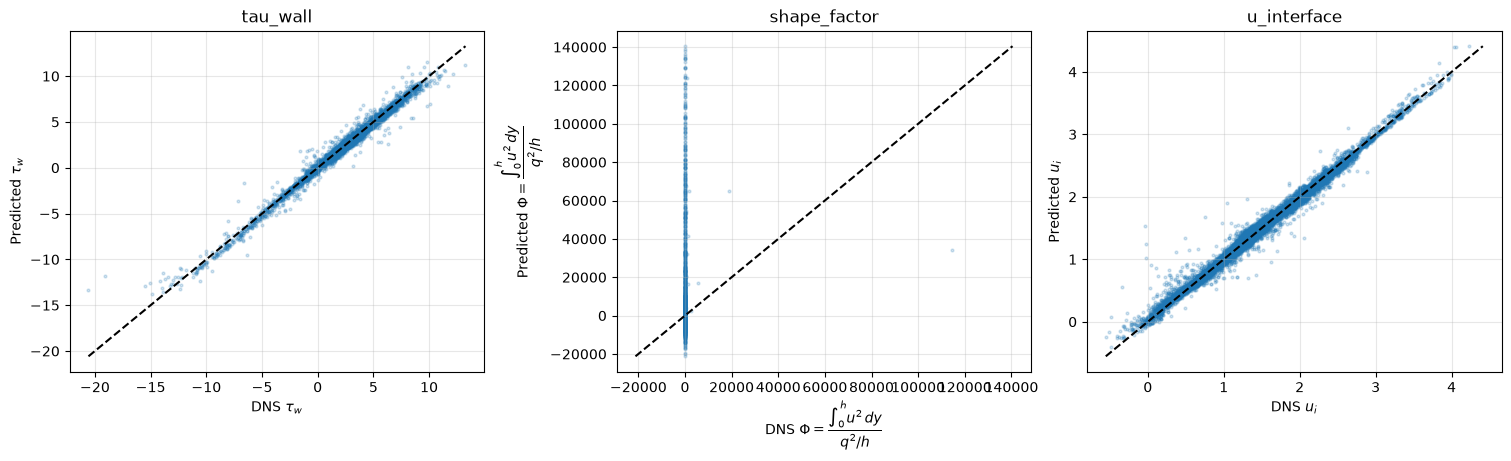

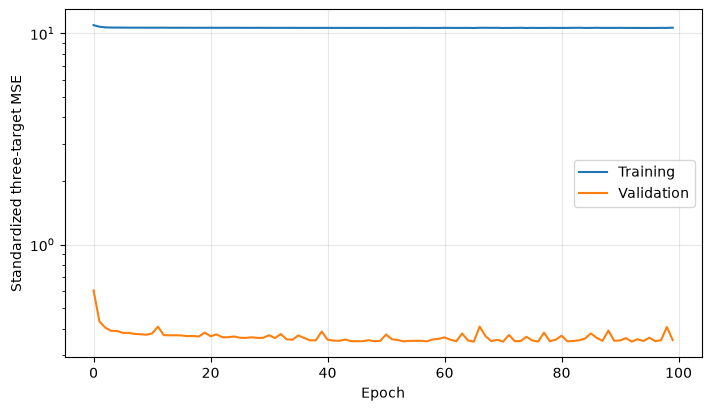

In [20]:

fig, axes = plt.subplots(1, len(target_names), figsize=(15, 4.5), constrained_layout=True)
rng_plot = np.random.default_rng(random_seed)
idx = rng_plot.choice(len(Y_true), min(len(Y_true), 30000), replace=False)

for j, (name, label) in enumerate(zip(target_names, target_labels)):
    truth, pred = Y_true[idx, j], Y_pred[idx, j]
    lo, hi = min(truth.min(), pred.min()), max(truth.max(), pred.max())
    axes[j].scatter(truth, pred, s=4, alpha=0.2)
    axes[j].plot([lo, hi], [lo, hi], "--", color="black")
    axes[j].set_title(name)
    axes[j].set_xlabel(f"DNS {label}")
    axes[j].set_ylabel(f"Predicted {label}")
    axes[j].grid(True, alpha=0.3)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.plot(train_losses, label="Training")
ax.plot(val_losses, label="Validation")
ax.set_yscale("log")
ax.set_xlabel("Epoch")
ax.set_ylabel("Standardized three-target MSE")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()
